# Task 1

In [1]:
%pip install torch torchvision

In [2]:
import torch
import torchvision

print(torch.__version__)
print("PyTorch loaded successfully!")

2.11.0+cpu
PyTorch loaded successfully!


#Task 2

In [3]:
import torchvision
import torchvision.transforms as transforms

transform = transforms.ToTensor()

train_dataset = torchvision.datasets.MNIST(
    root="./data",
    train=True,
    download=True,
    transform=transform
)

test_dataset = torchvision.datasets.MNIST(
    root="./data",
    train=False,
    download=True,
    transform=transform
)

print("Dataset loaded successfully!")
print("Training samples:", len(train_dataset))
print("Testing samples:", len(test_dataset))

100%|██████████| 9.91M/9.91M [00:00<00:00, 37.1MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 1.08MB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 9.37MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 11.4MB/s]

Dataset loaded successfully!
Training samples: 60000
Testing samples: 10000


# Task 3

In [4]:
from torch.utils.data import DataLoader

train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True)

images, labels = next(iter(train_loader))

print("Images tensor size:", images.shape)
print("Labels tensor size:", labels.shape)

Images tensor size: torch.Size([32, 1, 28, 28])
Labels tensor size: torch.Size([32])


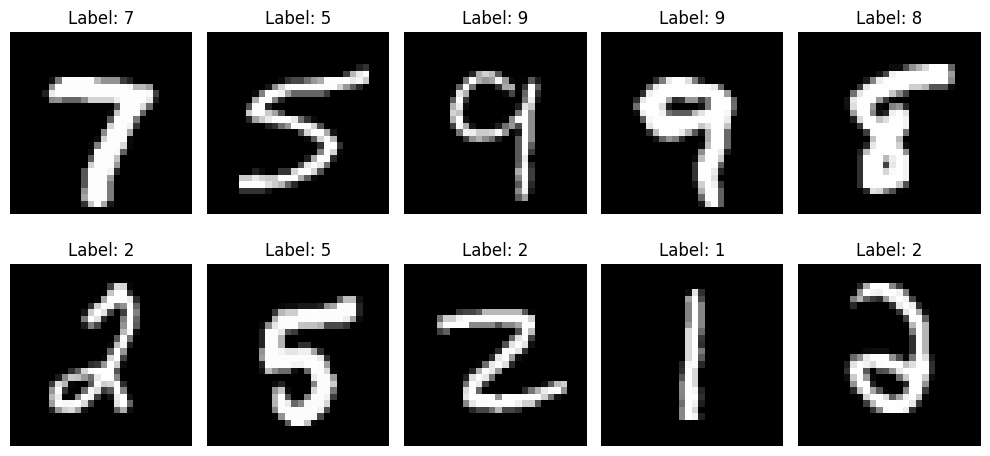

In [5]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(2, 5, figsize=(10, 5))

for i, ax in enumerate(axes.flat):
    ax.imshow(images[i].squeeze(), cmap='gray')
    ax.set_title(f"Label: {labels[i].item()}")
    ax.axis('off')

plt.tight_layout()
plt.show()

# Task 4

In [6]:

# Task 4: Creating a Simple Neural Network

import torch
import torch.nn as nn

class SimpleNet(nn.Module):
    def __init__(self):
        super(SimpleNet, self).__init__()

        self.flatten = nn.Flatten()
        self.fc1 = nn.Linear(784, 128)
        self.relu = nn.ReLU()
        self.fc2 = nn.Linear(128, 10)

    def forward(self, x):
        x = self.flatten(x)
        x = self.fc1(x)
        x = self.relu(x)
        x = self.fc2(x)
        return x

# Create the network
net = SimpleNet()

print("Neural Network Architecture:")
print(net)

# Verify the input and output shapes
images, labels = next(iter(train_loader))

outputs = net(images)

print("\nInput Shape:", images.shape)
print("Flattened Shape:", torch.flatten(images, start_dim=1).shape)
print("Output Shape:", outputs.shape)


Neural Network Architecture:
SimpleNet(
  (flatten): Flatten(start_dim=1, end_dim=-1)
  (fc1): Linear(in_features=784, out_features=128, bias=True)
  (relu): ReLU()
  (fc2): Linear(in_features=128, out_features=10, bias=True)
)

Input Shape: torch.Size([32, 1, 28, 28])
Flattened Shape: torch.Size([32, 784])
Output Shape: torch.Size([32, 10])


# Task 5


In [7]:

# Task 5: Training Function

import torch.optim as optim

def train(net, train_loader, epochs=5, learning_rate=0.01, momentum=0.9):

    criterion = nn.CrossEntropyLoss()

    optimizer = optim.SGD(
        net.parameters(),
        lr=learning_rate,
        momentum=momentum
    )

    batch_losses = []
    epoch_losses = []
    epoch_accuracies = []

    net.train()

    for epoch in range(epochs):

        running_loss = 0.0
        correct = 0
        total = 0

        for batch_idx, (images, labels) in enumerate(train_loader):

            # Reset gradients
            optimizer.zero_grad()

            # Forward pass
            outputs = net(images)

            # Calculate loss
            loss = criterion(outputs, labels)

            # Backpropagation
            loss.backward()

            # Update weights
            optimizer.step()

            # Record mini-batch loss
            batch_losses.append(loss.item())
            running_loss += loss.item()

            # Calculate accuracy
            _, predicted = torch.max(outputs, 1)

            total += labels.size(0)
            correct += (predicted == labels).sum().item()

            # Print training progress
            if (batch_idx + 1) % 200 == 0:
                print(
                    f"Epoch [{epoch+1}/{epochs}], "
                    f"Batch [{batch_idx+1}/{len(train_loader)}], "
                    f"Loss: {loss.item():.4f}, "
                    f"Accuracy: {100 * correct / total:.2f}%"
                )

        # Average loss and accuracy per epoch
        avg_loss = running_loss / len(train_loader)
        accuracy = 100 * correct / total

        epoch_losses.append(avg_loss)
        epoch_accuracies.append(accuracy)

        print(
            f"\nEpoch {epoch+1}/{epochs} Completed | "
            f"Average Loss: {avg_loss:.4f} | "
            f"Accuracy: {accuracy:.2f}%\n"
        )

    return batch_losses, epoch_losses, epoch_accuracies


# Task 6


In [8]:

# Task 6: Training the Network

# Instantiate a new neural network
net = SimpleNet()

# Train the network
batch_losses, epoch_losses, epoch_accuracies = train(
    net,
    train_loader,
    epochs=5,
    learning_rate=0.01,
    momentum=0.9
)

print("Training Completed Successfully!")


Epoch [1/5], Batch [200/1875], Loss: 0.4438, Accuracy: 73.55%
Epoch [1/5], Batch [400/1875], Loss: 0.6769, Accuracy: 80.99%
Epoch [1/5], Batch [600/1875], Loss: 0.3410, Accuracy: 83.99%
Epoch [1/5], Batch [800/1875], Loss: 0.2017, Accuracy: 85.88%
Epoch [1/5], Batch [1000/1875], Loss: 0.0858, Accuracy: 87.03%
Epoch [1/5], Batch [1200/1875], Loss: 0.1988, Accuracy: 87.92%
Epoch [1/5], Batch [1400/1875], Loss: 0.2193, Accuracy: 88.65%
Epoch [1/5], Batch [1600/1875], Loss: 0.1624, Accuracy: 89.15%
Epoch [1/5], Batch [1800/1875], Loss: 0.1853, Accuracy: 89.65%

Epoch 1/5 Completed | Average Loss: 0.3615 | Accuracy: 89.81%

Epoch [2/5], Batch [200/1875], Loss: 0.2819, Accuracy: 94.36%
Epoch [2/5], Batch [400/1875], Loss: 0.2213, Accuracy: 94.64%
Epoch [2/5], Batch [600/1875], Loss: 0.2802, Accuracy: 94.79%
Epoch [2/5], Batch [800/1875], Loss: 0.1703, Accuracy: 94.98%
Epoch [2/5], Batch [1000/1875], Loss: 0.1864, Accuracy: 95.01%
Epoch [2/5], Batch [1200/1875], Loss: 0.0750, Accuracy: 95.15%

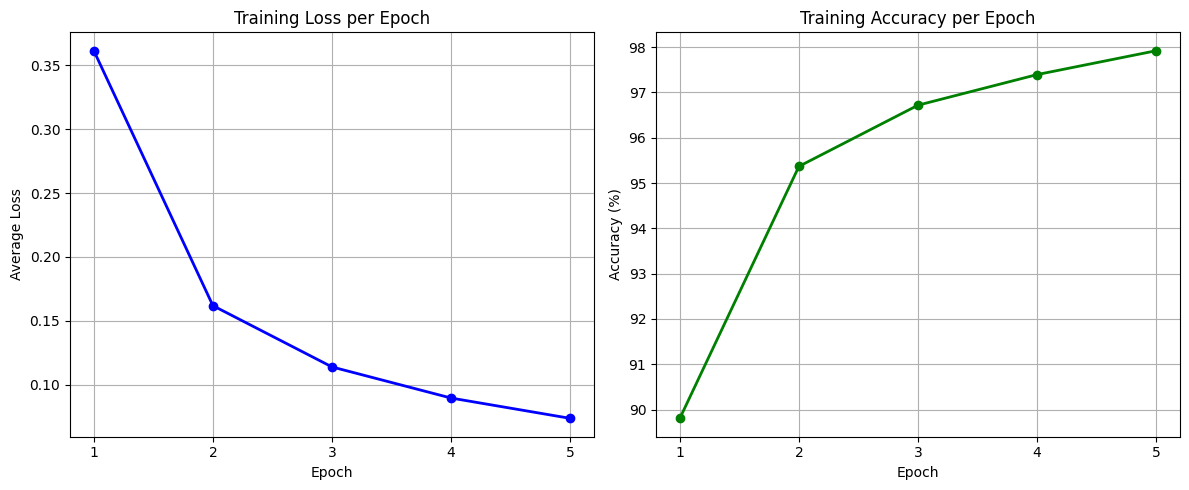

In [9]:

# Task 6: Plot Training Loss and Accuracy

import matplotlib.pyplot as plt

epochs_range = range(1, len(epoch_losses) + 1)

plt.figure(figsize=(12, 5))

# Training Loss
plt.subplot(1, 2, 1)
plt.plot(epochs_range, epoch_losses,
         marker='o', color='blue', linewidth=2)
plt.title("Training Loss per Epoch")
plt.xlabel("Epoch")
plt.ylabel("Average Loss")
plt.xticks(epochs_range)
plt.grid(True)

# Training Accuracy
plt.subplot(1, 2, 2)
plt.plot(epochs_range, epoch_accuracies,
         marker='o', color='green', linewidth=2)
plt.title("Training Accuracy per Epoch")
plt.xlabel("Epoch")
plt.ylabel("Accuracy (%)")
plt.xticks(epochs_range)
plt.grid(True)

plt.tight_layout()
plt.show()


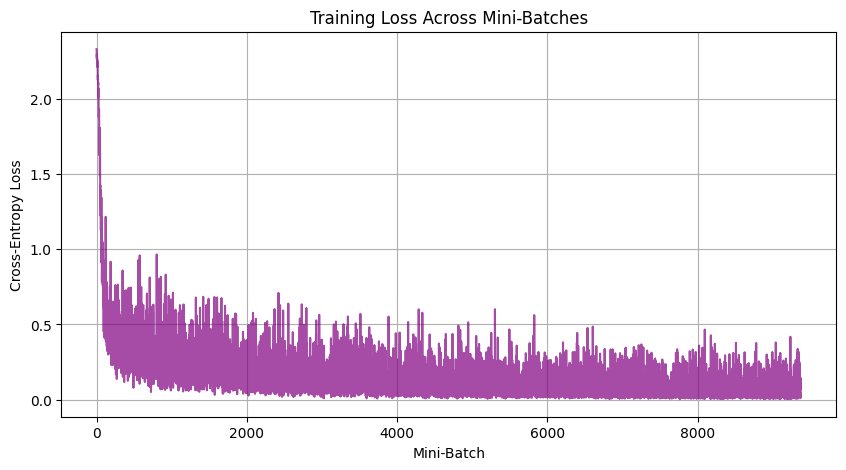

In [10]:

# Task 6: Mini-Batch Training Loss

plt.figure(figsize=(10, 5))

plt.plot(batch_losses, color='purple', alpha=0.7)

plt.title("Training Loss Across Mini-Batches")
plt.xlabel("Mini-Batch")
plt.ylabel("Cross-Entropy Loss")
plt.grid(True)

plt.show()


# Task 7


In [12]:

# Create the MNIST test DataLoader if not already defined

from torchvision import datasets, transforms
from torch.utils.data import DataLoader

test_dataset = datasets.MNIST(
    root="./data",
    train=False,
    download=True,
    transform=transforms.ToTensor()
)

test_loader = DataLoader(
    test_dataset,
    batch_size=32,
    shuffle=False
)


In [13]:

# Task 7: Testing the Neural Network

import torch
import matplotlib.pyplot as plt

# Switch model to evaluation mode
net.eval()

correct = 0
total = 0

# Evaluate the model using the MNIST test dataset
with torch.no_grad():
    for images, labels in test_loader:
        outputs = net(images)
        _, predicted = torch.max(outputs, 1)

        total += labels.size(0)
        correct += (predicted == labels).sum().item()

test_accuracy = 100 * correct / total

print(f"Total Test Images: {total}")
print(f"Correct Predictions: {correct}")
print(f"Test Accuracy: {test_accuracy:.2f}%")


Total Test Images: 10000
Correct Predictions: 9733
Test Accuracy: 97.33%


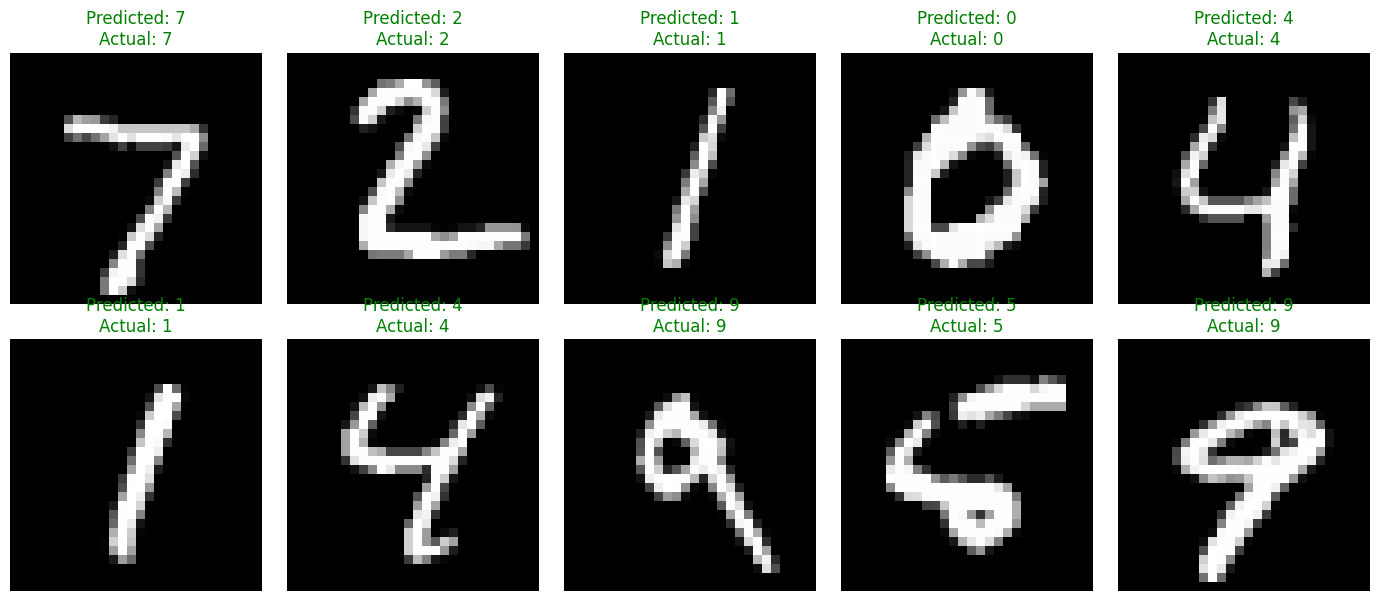

In [14]:

# Task 7: Visualize Model Predictions

net.eval()

images, labels = next(iter(test_loader))

with torch.no_grad():
    outputs = net(images)
    _, predictions = torch.max(outputs, 1)

plt.figure(figsize=(14, 6))

for i in range(10):
    plt.subplot(2, 5, i + 1)

    plt.imshow(images[i].squeeze(), cmap="gray")

    predicted = predictions[i].item()
    actual = labels[i].item()

    plt.title(
        f"Predicted: {predicted}\nActual: {actual}",
        color="green" if predicted == actual else "red"
    )

    plt.axis("off")

plt.tight_layout()
plt.show()


# Task 8

In [15]:

# Task 8: Prepare Validation Data

from torch.utils.data import DataLoader, random_split

full_train_dataset = train_loader.dataset

train_size = int(0.8 * len(full_train_dataset))
val_size = len(full_train_dataset) - train_size

train_subset, val_subset = random_split(
    full_train_dataset,
    [train_size, val_size],
    generator=torch.Generator().manual_seed(42)
)

tuning_train_loader = DataLoader(
    train_subset,
    batch_size=32,
    shuffle=True
)

val_loader = DataLoader(
    val_subset,
    batch_size=32,
    shuffle=False
)

def evaluate_model(model, data_loader):
    model.eval()

    criterion = nn.CrossEntropyLoss()
    total_loss = 0.0
    correct = 0
    total = 0

    with torch.no_grad():
        for images, labels in data_loader:
            outputs = model(images)
            loss = criterion(outputs, labels)

            total_loss += loss.item() * labels.size(0)

            _, predicted = torch.max(outputs, 1)
            total += labels.size(0)
            correct += (predicted == labels).sum().item()

    avg_loss = total_loss / total
    accuracy = 100 * correct / total

    return avg_loss, accuracy

print("Training samples:", train_size)
print("Validation samples:", val_size)


Training samples: 48000
Validation samples: 12000


In [16]:

# Task 8: Learning Rate and Momentum Tuning

import pandas as pd

learning_rates = [0.001, 0.01, 0.1]
momentum_values = [0.0, 0.9]

parameter_results = []

for lr in learning_rates:
    for mom in momentum_values:

        print(f"\nTraining: LR={lr}, Momentum={mom}")

        torch.manual_seed(42)
        model = SimpleNet()

        train(
            model,
            tuning_train_loader,
            epochs=5,
            learning_rate=lr,
            momentum=mom
        )

        val_loss, val_accuracy = evaluate_model(
            model, val_loader
        )

        parameter_results.append({
            "Learning Rate": lr,
            "Momentum": mom,
            "Validation Loss": val_loss,
            "Validation Accuracy (%)": val_accuracy
        })

parameter_df = pd.DataFrame(parameter_results)

parameter_df = parameter_df.sort_values(
    by=["Validation Accuracy (%)", "Validation Loss"],
    ascending=[False, True]
)

print("\nParameter Tuning Results:")
print(parameter_df.to_string(index=False))

best_parameters = parameter_df.iloc[0]

best_lr = float(best_parameters["Learning Rate"])
best_momentum = float(best_parameters["Momentum"])

print("\nBest Learning Rate:", best_lr)
print("Best Momentum:", best_momentum)



Training: LR=0.001, Momentum=0.0
Epoch [1/5], Batch [200/1500], Loss: 2.2548, Accuracy: 13.83%
Epoch [1/5], Batch [400/1500], Loss: 2.2208, Accuracy: 17.24%
Epoch [1/5], Batch [600/1500], Loss: 2.1705, Accuracy: 21.80%
Epoch [1/5], Batch [800/1500], Loss: 2.1544, Accuracy: 26.45%
Epoch [1/5], Batch [1000/1500], Loss: 2.0646, Accuracy: 30.94%
Epoch [1/5], Batch [1200/1500], Loss: 2.0217, Accuracy: 35.13%
Epoch [1/5], Batch [1400/1500], Loss: 1.9837, Accuracy: 38.96%

Epoch 1/5 Completed | Average Loss: 2.1364 | Accuracy: 40.64%

Epoch [2/5], Batch [200/1500], Loss: 1.8785, Accuracy: 66.55%
Epoch [2/5], Batch [400/1500], Loss: 1.8815, Accuracy: 68.21%
Epoch [2/5], Batch [600/1500], Loss: 1.7950, Accuracy: 69.14%
Epoch [2/5], Batch [800/1500], Loss: 1.6825, Accuracy: 69.73%
Epoch [2/5], Batch [1000/1500], Loss: 1.4771, Accuracy: 70.28%
Epoch [2/5], Batch [1200/1500], Loss: 1.4723, Accuracy: 70.88%
Epoch [2/5], Batch [1400/1500], Loss: 1.4435, Accuracy: 71.41%

Epoch 2/5 Completed | Avera

In [17]:

# Task 8: Architecture Tuning

class FlexibleNet(nn.Module):

    def __init__(self, hidden_layers):
        super(FlexibleNet, self).__init__()

        layers = [nn.Flatten()]

        input_size = 784

        for neurons in hidden_layers:
            layers.append(nn.Linear(input_size, neurons))
            layers.append(nn.ReLU())
            input_size = neurons

        layers.append(nn.Linear(input_size, 10))

        self.network = nn.Sequential(*layers)

    def forward(self, x):
        return self.network(x)


architectures = [
    [64],          # 1 hidden layer, 64 neurons
    [128],         # 1 hidden layer, 128 neurons
    [256],         # 1 hidden layer, 256 neurons
    [128, 64],     # 2 hidden layers
    [256, 128],    # 2 hidden layers
    [256, 128, 64] # 3 hidden layers
]

architecture_results = []

for architecture in architectures:

    print(f"\nTraining Architecture: {architecture}")

    torch.manual_seed(42)
    model = FlexibleNet(architecture)

    train(
        model,
        tuning_train_loader,
        epochs=5,
        learning_rate=best_lr,
        momentum=best_momentum
    )

    val_loss, val_accuracy = evaluate_model(
        model, val_loader
    )

    architecture_results.append({
        "Hidden Layers": len(architecture),
        "Neurons": str(architecture),
        "Validation Loss": val_loss,
        "Validation Accuracy (%)": val_accuracy
    })

architecture_df = pd.DataFrame(architecture_results)

architecture_df = architecture_df.sort_values(
    by=["Validation Accuracy (%)", "Validation Loss"],
    ascending=[False, True]
)

print("\nArchitecture Tuning Results:")
print(architecture_df.to_string(index=False))

best_architecture = architecture_df.iloc[0]

print("\nBest Architecture:")
print(best_architecture.to_string())



Training Architecture: [64]
Epoch [1/5], Batch [200/1500], Loss: 0.2730, Accuracy: 75.39%
Epoch [1/5], Batch [400/1500], Loss: 0.7769, Accuracy: 81.70%
Epoch [1/5], Batch [600/1500], Loss: 0.1837, Accuracy: 84.70%
Epoch [1/5], Batch [800/1500], Loss: 0.3932, Accuracy: 86.16%
Epoch [1/5], Batch [1000/1500], Loss: 0.1586, Accuracy: 87.28%
Epoch [1/5], Batch [1200/1500], Loss: 0.5042, Accuracy: 88.17%
Epoch [1/5], Batch [1400/1500], Loss: 0.2252, Accuracy: 88.87%

Epoch 1/5 Completed | Average Loss: 0.3847 | Accuracy: 89.16%

Epoch [2/5], Batch [200/1500], Loss: 0.2637, Accuracy: 94.78%
Epoch [2/5], Batch [400/1500], Loss: 0.0986, Accuracy: 94.30%
Epoch [2/5], Batch [600/1500], Loss: 0.4059, Accuracy: 94.38%
Epoch [2/5], Batch [800/1500], Loss: 0.3261, Accuracy: 94.41%
Epoch [2/5], Batch [1000/1500], Loss: 0.1967, Accuracy: 94.46%
Epoch [2/5], Batch [1200/1500], Loss: 0.2682, Accuracy: 94.54%
Epoch [2/5], Batch [1400/1500], Loss: 0.1775, Accuracy: 94.66%

Epoch 2/5 Completed | Average Lo

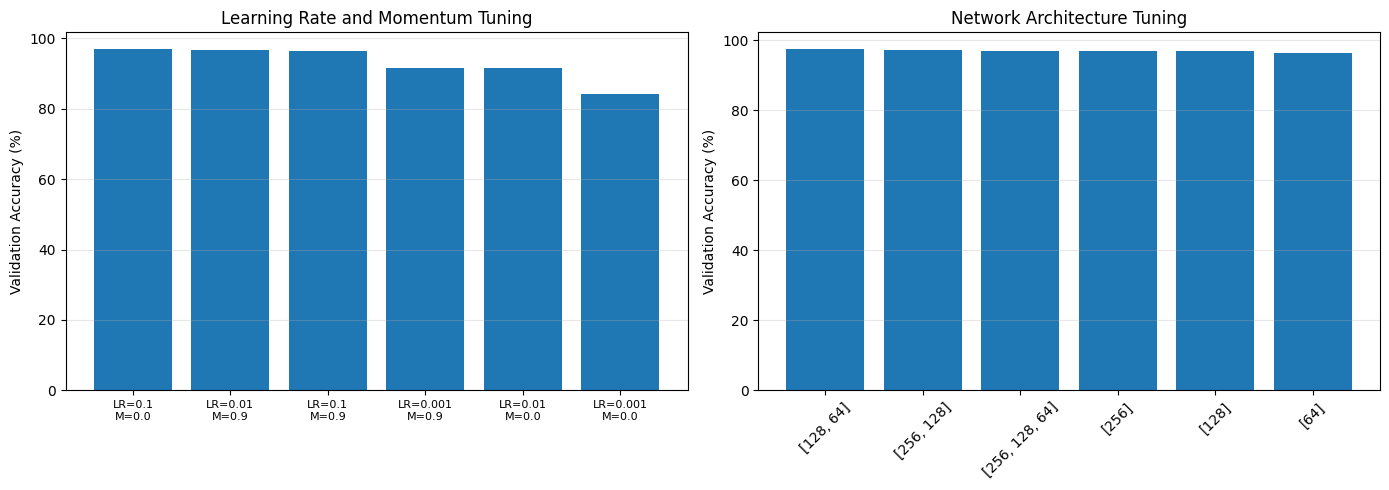

In [18]:

# Task 8: Visualize Tuning Results

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

parameter_labels = [
    f"LR={row['Learning Rate']}\nM={row['Momentum']}"
    for _, row in parameter_df.iterrows()
]

axes[0].bar(
    parameter_labels,
    parameter_df["Validation Accuracy (%)"]
)
axes[0].set_title("Learning Rate and Momentum Tuning")
axes[0].set_ylabel("Validation Accuracy (%)")
axes[0].tick_params(axis="x", labelsize=8)
axes[0].grid(axis="y", alpha=0.3)

axes[1].bar(
    architecture_df["Neurons"],
    architecture_df["Validation Accuracy (%)"]
)
axes[1].set_title("Network Architecture Tuning")
axes[1].set_ylabel("Validation Accuracy (%)")
axes[1].tick_params(axis="x", rotation=45)
axes[1].grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()


In [19]:

# Task 8: Final Best Model

import ast

best_hidden_layers = ast.literal_eval(
    best_architecture["Neurons"]
)

torch.manual_seed(42)

best_model = FlexibleNet(best_hidden_layers)

print("Best Architecture:", best_hidden_layers)
print("Best Learning Rate:", best_lr)
print("Best Momentum:", best_momentum)

# Train using all original training data
train(
    best_model,
    train_loader,
    epochs=5,
    learning_rate=best_lr,
    momentum=best_momentum
)

# Final evaluation on the test data
final_test_loss, final_test_accuracy = evaluate_model(
    best_model,
    test_loader
)

print("\nFINAL BEST MODEL RESULTS")
print(f"Test Loss: {final_test_loss:.4f}")
print(f"Test Accuracy: {final_test_accuracy:.2f}%")


Best Architecture: [128, 64]
Best Learning Rate: 0.1
Best Momentum: 0.0
Epoch [1/5], Batch [200/1875], Loss: 0.5116, Accuracy: 65.06%
Epoch [1/5], Batch [400/1875], Loss: 0.3036, Accuracy: 76.11%
Epoch [1/5], Batch [600/1875], Loss: 0.1214, Accuracy: 80.86%
Epoch [1/5], Batch [800/1875], Loss: 0.3307, Accuracy: 83.62%
Epoch [1/5], Batch [1000/1875], Loss: 0.0744, Accuracy: 85.26%
Epoch [1/5], Batch [1200/1875], Loss: 0.3743, Accuracy: 86.61%
Epoch [1/5], Batch [1400/1875], Loss: 0.0586, Accuracy: 87.64%
Epoch [1/5], Batch [1600/1875], Loss: 0.3939, Accuracy: 88.45%
Epoch [1/5], Batch [1800/1875], Loss: 0.1542, Accuracy: 89.13%

Epoch 1/5 Completed | Average Loss: 0.3586 | Accuracy: 89.35%

Epoch [2/5], Batch [200/1875], Loss: 0.1389, Accuracy: 95.59%
Epoch [2/5], Batch [400/1875], Loss: 0.4657, Accuracy: 95.72%
Epoch [2/5], Batch [600/1875], Loss: 0.1102, Accuracy: 95.69%
Epoch [2/5], Batch [800/1875], Loss: 0.2268, Accuracy: 95.81%
Epoch [2/5], Batch [1000/1875], Loss: 0.1302, Accurac